<a href="https://colab.research.google.com/github/Tri8505/ML-Assignment-Adult-Census/blob/main/notebooks/main_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adult Census Income Classification
### Traditional Machine Learning and Deep Learning

**Objective.** Predict whether annual income exceeds USD 50,000 using the official UCI Adult train/test split. Select models by stratified three-fold cross-validation (CV) macro-F1, then compare two frozen finalists on the test partition.

**Evaluation scope.** The UCI test partition has been examined in earlier development. This is a follow-up benchmark, not a newly collected or previously unseen external validation set. No test-based tuning is performed in this run.

## 1. Environment

Install missing dependencies before importing the experiment modules.

In [5]:
from pathlib import Path
import importlib.metadata as metadata
import importlib.util
import os
import subprocess
import sys
import time

DEPENDENCIES = {
    "numpy": ">=1.26,<3", "pandas": ">=2.2,<3", "scikit-learn": ">=1.4,<2",
    "matplotlib": ">=3.8,<4", "seaborn": ">=0.13,<1", "torch": ">=2.6,<3",
    "joblib": ">=1.3,<2", "threadpoolctl": ">=3,<4",
}
if importlib.util.find_spec("packaging") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "packaging"], check=True)
from packaging.specifiers import SpecifierSet
missing = []
for package, constraint in DEPENDENCIES.items():
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = None
    if version is None or version not in SpecifierSet(constraint):
        missing.append(package + constraint)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(variable, "2")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
SEED, DEVICE = 42, "cpu"
BASE_DIR = Path("/content") if Path("/content").is_dir() else Path.cwd()
PROJECT_DIR = BASE_DIR / "adult_census_english"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

from IPython.display import display, Markdown, FileLink
display(Markdown(f"**Environment ready.** Python {sys.version.split()[0]}; device: {DEVICE}. "
                 "All package versions will be recorded with the results."))

**Environment ready.** Python 3.13.18; device: cpu. All package versions will be recorded with the results.

## 2. Reproducible experiment setup

Verify external modules and create an isolated output directory for this run.

In [6]:
import ast
import hashlib
import importlib
import json
from urllib.request import Request, urlopen
from zipfile import ZipFile, ZIP_DEFLATED
import sys
import time
from pathlib import Path

SOURCE_REF = '3377a022e50ba279ee24d582b666a24b8856c524'
SOURCE_HASHES = {'modules/__init__.py': 'c2a6acdaa47d61821696dbe7ba8edf908e8c313cf054f455f01a8b8bc4e4bef8', 'modules/data_loader.py': 'ae4b1f8a965ac869e159fb51a50ce443c03dd13d3ae5552200fd96549c10bca4', 'modules/eda.py': 'b1008970aa26b778a78f7cc55684e0b36ae501c50e43f60237e715839ab654f3', 'modules/preprocessor.py': '2bc3a0008a72d55b45b8bc24dce1b351d3224e792157432b74aa3a43bba8924c', 'modules/traditional_models.py': '3aa7ab542deaff5c2b679c2b4319b9feac28052df51f0f0b5759b74497425ee6', 'modules/deep_learning_models.py': 'c7f97f77aab2707810b21a056decac346f92c62624b15338a490d0e5f5207390'}
BUNDLE_NAME = 'adult_census_colab_english.zip'

def normalized_source(data):
    return data.decode("utf-8-sig").replace("\r\n", "\n").rstrip() + "\n"

def verified_source(data, expected, bypass_hash=False):
    text = normalized_source(data)
    if not bypass_hash:
        if hashlib.sha256(text.encode()).hexdigest() != expected:
            return None
    ast.parse(text)
    return text

def fetch_source(url):
    last_error = None
    for attempt in range(3):
        try:
            with urlopen(Request(url, headers={"User-Agent": "AdultCensus-Notebook/1.0"}), timeout=45) as response:
                return response.read()
        except OSError as error:
            last_error = error
            if attempt < 2:
                time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"Could not download source: {url}") from last_error

source_origins = []
for relative, expected in SOURCE_HASHES.items():
    destination = PROJECT_DIR / relative
    candidates = [BASE_DIR / relative, BASE_DIR.parent / relative, destination]
    is_dl_model = relative.endswith("deep_learning_models.py")
    if is_dl_model:
        candidates.insert(0, BASE_DIR / "deep_learning_models.py")
    source, origin = None, None
    for candidate in candidates:
        if candidate.is_file():
            source = verified_source(candidate.read_bytes(), expected, bypass_hash=is_dl_model)
            if source is not None:
                origin = str(candidate)
                break
    if source is None and (BASE_DIR / BUNDLE_NAME).is_file():
        with ZipFile(BASE_DIR / BUNDLE_NAME) as bundle:
            if relative in bundle.namelist():
                source = verified_source(bundle.read(relative), expected, bypass_hash=is_dl_model)
                if source is not None:
                    origin = f"{BUNDLE_NAME}:{relative}"
    if source is None:
        ref = "main" if is_dl_model else SOURCE_REF
        url = f"https://raw.githubusercontent.com/Tri8505/ML-Assignment-Adult-Census/{ref}/{relative}"
        try:
            source = verified_source(fetch_source(url), expected, bypass_hash=is_dl_model)
        except RuntimeError:
            if not is_dl_model:
                raise
        if source is not None:
            origin = url
    if source is None:
        raise FileNotFoundError(
            f"The verified version of {relative} is missing. Upload {BUNDLE_NAME} "
            "to the Colab Files panel, then run all cells again. An older module cannot be substituted."
        )
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(source, encoding="utf-8")

    # Calculate actual sha256 to save in origins
    actual_sha = hashlib.sha256(source.encode()).hexdigest()
    source_origins.append({"module": relative, "origin": origin, "sha256": actual_sha})

for name in list(sys.modules):
    if name == "modules" or name.startswith("modules."):
        del sys.modules[name]
if str(PROJECT_DIR) in sys.path:
    sys.path.remove(str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR))
importlib.invalidate_caches()

import contextlib
from dataclasses import asdict
from datetime import datetime, timezone
import platform
import shutil
import textwrap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from threadpoolctl import threadpool_limits
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
from modules.data_loader import load_adult_data
from modules.eda import dataset_overview
from modules.preprocessor import prepare_xy, export_features
from modules.traditional_models import (
    run_baselines, run_model_comparison, run_preprocessing_comparison,
    tune_random_forest, summarize_search, evaluate_test,
)
from modules import deep_learning_models as dl

assert dl.API_VERSION == 3 and len(dl.DEFAULT_CONFIGS) == 16
assert Path(dl.__file__).resolve() == (PROJECT_DIR / "modules/deep_learning_models.py").resolve()
torch.set_num_threads(2)
thread_limits = threadpool_limits(limits=2)
dl.seed_everything(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 80)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
RUN_DIR = PROJECT_DIR / "runs" / RUN_ID
RESULTS, FIGURES, MODELS, FEATURES, LOGS = [RUN_DIR / name for name in (
    "results", "figures", "models", "features", "logs")]
for directory in (RESULTS, FIGURES, MODELS, FEATURES, LOGS):
    directory.mkdir(parents=True, exist_ok=True)
timings = []

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")

def interpret(text):
    display(Markdown("**Interpretation.** " + text))

def table(frame, filename, columns=None):
    frame.to_csv(RESULTS / f"{filename}.csv", index=True)
    shown = frame if columns is None else frame.loc[:, columns]
    display(shown.round(4))

def figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{filename}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def timed(label, function, *args, **kwargs):
    started = time.perf_counter()
    status = display(Markdown(f"*Running {label}...*"), display_id=True)
    with (LOGS / f"{label}.log").open("w", encoding="utf-8") as log, contextlib.redirect_stdout(log):
        result = function(*args, **kwargs)
    seconds = time.perf_counter() - started
    timings.append({"stage": label, "seconds": seconds})
    status.update(Markdown(f"*Completed {label} in {seconds:.1f} seconds.*"))
    return result

environment = {"python": platform.python_version(), "platform": platform.platform(),
    "versions": {name: metadata.version(name) for name in DEPENDENCIES},
    "device": DEVICE, "torch_threads": torch.get_num_threads(), "seed": SEED,
    "base_source_commit": SOURCE_REF, "sources": source_origins, "run_id": RUN_ID}
save_json(RESULTS / "environment.json", environment)
display(pd.Series(environment["versions"], name="version").to_frame())
interpret("The base modules and the enhanced neural module passed source-integrity checks. "
          "The experiment uses a fixed CPU configuration and records versions and source hashes for reproducibility.")

,version
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
seaborn,0.13.2
torch,2.14.1+cpu
joblib,1.6.0
threadpoolctl,3.7.0


**Interpretation.** The base modules and the enhanced neural module passed source-integrity checks. The experiment uses a fixed CPU configuration and records versions and source hashes for reproducibility.

## 3. Data integrity

Retain the official UCI partitions. Exploratory analysis and model selection use training data only.

In [7]:
train_df, test_df = load_adult_data(data_dir=PROJECT_DIR / "data/raw")
assert train_df.shape == (32561, 15) and test_df.shape == (16281, 15)
assert train_df.columns.equals(test_df.columns)
for frame in (train_df, test_df):
    assert frame["income"].notna().all()
    assert set(frame["income"].unique()) == {"<=50K", ">50K"}
overview = dataset_overview(train_df)
audit = pd.DataFrame([
    {"partition": "Train", "rows": len(train_df), "features": 14, "use": "EDA, CV and final fitting"},
    {"partition": "Test", "rows": len(test_df), "features": 14, "use": "Frozen-finalist evaluation only"},
]).set_index("partition")
table(audit, "data_audit")
interpret(f"Both partitions have the expected schema and normalized labels. Training data contain "
          f"{overview['duplicate_rows']} exact duplicate rows; these are retained to preserve the official split. "
          "Their influence is not isolated in this experiment.")
save_json(RESULTS / "data_provenance.json", {
    "dataset": "UCI Adult", "url": "https://archive.ics.uci.edu/dataset/2/adult",
    "train_rows": len(train_df), "test_rows": len(test_df), "train_duplicate_rows": overview["duplicate_rows"],
    "files": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
              for p in sorted((PROJECT_DIR / "data/raw").glob("adult.*"))},
})

,rows,features,use
partition,,,
Train,32561,14,"EDA, CV and final fitting"
Test,16281,14,Frozen-finalist evaluation only


**Interpretation.** Both partitions have the expected schema and normalized labels. Training data contain 24 exact duplicate rows; these are retained to preserve the official split. Their influence is not isolated in this experiment.

## 4. Target distribution

Treat income >50K as the positive class. Report macro-F1 and class-specific precision and recall alongside accuracy.

,count,percent
income,,
<=50K,24720,75.919
>50K,7841,24.081


**Interpretation.** The positive class accounts for 24.08% of training rows. Always predicting <=50K would achieve 75.92% training accuracy without identifying any >50K cases. Macro-F1 therefore guides selection, while precision and recall describe the trade-off.

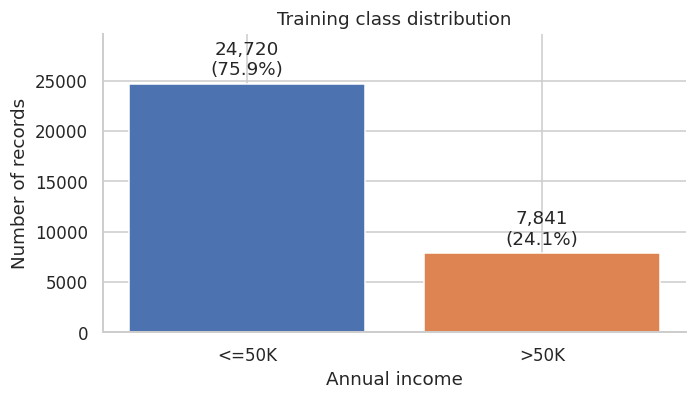

**Interpretation.** The imbalance motivates explicit evaluation of the minority class; it does not by itself justify assigning full inverse-frequency class weights.

In [8]:
distribution = overview["target_distribution"].reindex(["<=50K", ">50K"])
table(distribution, "train_target_distribution")
positive_share = float(distribution.loc[">50K", "percent"] / 100)
majority_share = float(distribution.loc["<=50K", "percent"] / 100)
interpret(f"The positive class accounts for {positive_share:.2%} of training rows. "
          f"Always predicting <=50K would achieve {majority_share:.2%} training accuracy without identifying any >50K cases. "
          "Macro-F1 therefore guides selection, while precision and recall describe the trade-off.")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(distribution.index, distribution["count"], color=["#4C72B0", "#DD8452"])
ax.bar_label(bars, labels=[f"{n:,}\n({p:.1f}%)" for n, p in zip(distribution["count"], distribution["percent"])], padding=3)
ax.set(title="Training class distribution", xlabel="Annual income", ylabel="Number of records")
ax.set_ylim(0, distribution["count"].max() * 1.2)
figure(fig, "target_distribution")
interpret("The imbalance motivates explicit evaluation of the minority class; it does not by itself justify assigning full inverse-frequency class weights.")

## 5. Missing values and feature types

Fit all imputation and encoding statistics within each training fold.

In [9]:
X_train, y_train = prepare_xy(train_df)
schema = pd.DataFrame({"type": X_train.dtypes.astype(str),
    "missing_count": X_train.isna().sum(), "missing_percent": X_train.isna().mean() * 100,
    "distinct_observed_values": X_train.nunique(dropna=True)})
table(schema, "feature_schema")
missing = schema.loc[schema["missing_count"] > 0].sort_values("missing_count", ascending=False)
missing_names = ", ".join(missing.index)
interpret(f"Missing values occur in {missing_names if len(missing) else 'no feature columns'}. "
          "Traditional pipelines compare mode and Unknown-category imputation. Neural pipelines use an Unknown category, "
          "median numeric imputation and encoders that accept unseen categories. No transformer is fitted on test data.")
categorical = X_train.select_dtypes(include=["object", "string", "category"])
category_profile = pd.DataFrame({"observed_categories": categorical.nunique(),
    "most_frequent_category": categorical.apply(lambda s: s.mode().iloc[0]),
    "largest_category_share": categorical.apply(lambda s: s.value_counts(normalize=True).iloc[0])})
table(category_profile, "categorical_profile")
interpret("Categorical fields have different cardinalities and frequency concentrations. One-hot encoding preserves category identity "
          "without imposing an artificial numeric order; unseen categories are handled by the fitted encoder.")

,type,missing_count,missing_percent,distinct_observed_values
age,int64,0,0.0000,73
workclass,object,1836,5.6386,8
fnlwgt,int64,0,0.0000,21648
education,object,0,0.0000,16
education_num,int64,0,0.0000,16
marital_status,object,0,0.0000,7
occupation,object,1843,5.6601,14
relationship,object,0,0.0000,6
race,object,0,0.0000,5
sex,object,0,0.0000,2


**Interpretation.** Missing values occur in occupation, workclass, native_country. Traditional pipelines compare mode and Unknown-category imputation. Neural pipelines use an Unknown category, median numeric imputation and encoders that accept unseen categories. No transformer is fitted on test data.

,observed_categories,most_frequent_category,largest_category_share
workclass,8,Private,0.7387
education,16,HS-grad,0.3225
marital_status,7,Married-civ-spouse,0.4599
occupation,14,Prof-specialty,0.1348
relationship,6,Husband,0.4052
race,5,White,0.8543
sex,2,Male,0.6692
native_country,41,United-States,0.9122


**Interpretation.** Categorical fields have different cardinalities and frequency concentrations. One-hot encoding preserves category identity without imposing an artificial numeric order; unseen categories are handled by the fitted encoder.

## 6. Numeric feature profiles

Describe training distributions without using test outcomes to design transformations.

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.5816,13.6404,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.3665,105549.9777,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.0807,2.5727,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.6488,7385.2921,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.3038,402.9602,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.4375,12.3474,1.0,40.0,40.0,45.0,99.0


**Interpretation.** Numeric features operate on different scales. capital gain is zero in 91.67% of training rows; capital loss is zero in 95.33% of training rows. These distributions motivate evaluating scaling and numerical encodings rather than assuming one transformation is optimal.

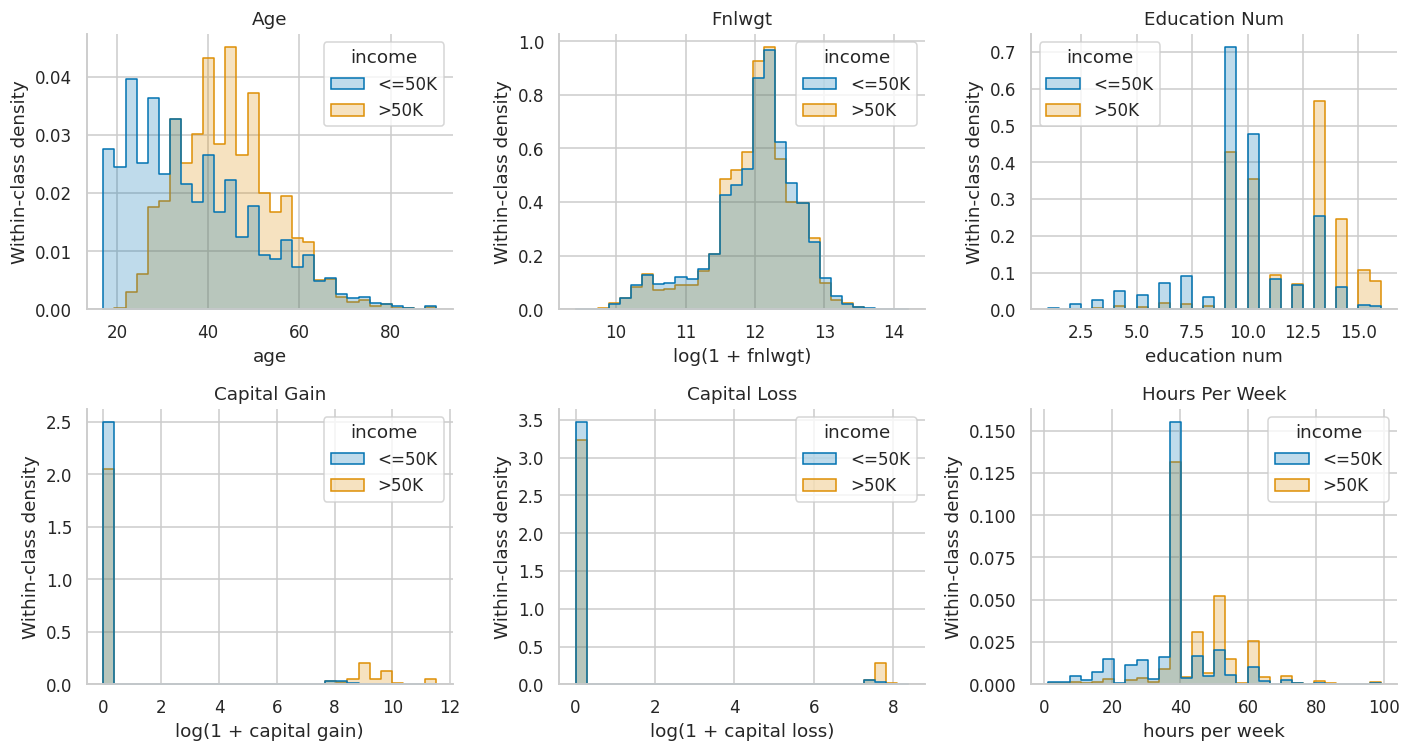

**Interpretation.** The panels compare class-conditional shapes rather than class sizes. Log axes are used only for visualization here; the model search independently evaluates standard, log, quantile and piecewise-linear representations. Associations are not causal effects.

In [10]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
table(X_train[numeric_columns].describe().T, "numeric_summary")
capital_columns = [name for name in ("capital_gain", "capital_loss") if name in X_train]
zero_share = {name: float(X_train[name].eq(0).mean()) for name in capital_columns}
interpret("Numeric features operate on different scales. " + "; ".join(
    f"{name.replace('_', ' ')} is zero in {share:.2%} of training rows" for name, share in zero_share.items()) +
    ". These distributions motivate evaluating scaling and numerical encodings rather than assuming one transformation is optimal.")
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, name in zip(axes.flat, numeric_columns):
    values = X_train[name]
    use_log = name in {"fnlwgt", "capital_gain", "capital_loss"}
    plotted = np.log1p(values) if use_log else values
    frame = pd.DataFrame({"value": plotted, "income": train_df["income"]})
    sns.histplot(frame, x="value", hue="income", hue_order=["<=50K", ">50K"],
                 bins=30, element="step", stat="density", common_norm=False, ax=ax)
    label = name.replace("_", " ")
    ax.set(title=label.title(), xlabel=f"log(1 + {label})" if use_log else label, ylabel="Within-class density")
figure(fig, "numeric_distributions")
interpret("The panels compare class-conditional shapes rather than class sizes. Log axes are used only for visualization here; "
          "the model search independently evaluates standard, log, quantile and piecewise-linear representations. Associations are not causal effects.")

## 7. Experimental protocol

Declare selection rules before fitting models or evaluating the test partition.

In [11]:
protocol = pd.DataFrame([
    ("Target mapping", "<=50K: 0; >50K: 1"),
    ("Outer CV", f"3 stratified folds; shuffled with seed {SEED}"),
    ("Selection metric", "Mean outer-CV macro-F1"),
    ("Neural early stopping", "15% stratified inner split; validation BCE objective"),
    ("Numeric representations", "Standard, log, quantile, piecewise linear"),
    ("Random Forest search", "12 configurations; 200 trees each"),
    ("Neural search", f"{len(dl.DEFAULT_CONFIGS)} configurations; 3-seed ensembles of the best two"),
    ("Final neural epochs", "Median selected fold epoch; same budget for each ensemble member"),
    ("Decision threshold", "0.5; unchanged throughout the experiment"),
    ("Finalist selection", "Tuned Random Forest vs best neural candidate; RF wins an exact CV tie"),
], columns=["item", "specification"]).set_index("item")
table(protocol, "protocol")
save_json(RESULTS / "search_plan_before_fit.json", {
    "seed": SEED, "device": DEVICE, "neural_configs": [asdict(c) for c in dl.DEFAULT_CONFIGS],
    "ensemble_top_k": 2, "threshold": 0.5, "test_used_for_selection": False,
    "test_previously_observed": True, "base_source_commit": SOURCE_REF,
    "deep_learning_sha256": SOURCE_HASHES["modules/deep_learning_models.py"],
})
interpret("Preprocessing and early stopping remain inside the outer training folds. Neural models use fewer rows for weight updates "
          "within each fold because of the inner split. CV scores guide configuration selection and may be optimistic after search; "
          "the two model families also receive different search budgets.")

,specification
item,
Target mapping,<=50K: 0; >50K: 1
Outer CV,3 stratified folds; shuffled with seed 42
Selection metric,Mean outer-CV macro-F1
Neural early stopping,15% stratified inner split; validation BCE objective
Numeric representations,"Standard, log, quantile, piecewise linear"
Random Forest search,12 configurations; 200 trees each
Neural search,16 configurations; 3-seed ensembles of the best two
Final neural epochs,Median selected fold epoch; same budget for each ensemble member
Decision threshold,0.5; unchanged throughout the experiment


**Interpretation.** Preprocessing and early stopping remain inside the outer training folds. Neural models use fewer rows for weight updates within each fold because of the inner split. CV scores guide configuration selection and may be optimistic after search; the two model families also receive different search budgets.

## 8. Baseline performance

Establish the majority-class and linear-model reference points.

In [12]:
baseline_results = timed("baselines", run_baselines, X_train, y_train, seed=SEED)
table(baseline_results, "baseline_cv", ["model", "cv_accuracy", "cv_f1_macro", "cv_f1_macro_std", "cv_precision_>50K", "cv_recall_>50K"])
base_by_name = baseline_results.set_index("model")
dummy, logistic = base_by_name.loc["Dummy"], base_by_name.loc["Logistic Regression"]
interpret(f"Logistic Regression achieves CV macro-F1 {logistic['cv_f1_macro']:.4f}, compared with "
          f"{dummy['cv_f1_macro']:.4f} for the majority baseline. The dummy classifier's positive-class recall is "
          f"{dummy['cv_recall_>50K']:.2%}, illustrating why accuracy alone is insufficient.")

*Completed baselines in 7.6 seconds.*

,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_precision_>50K,cv_recall_>50K
0,Logistic Regression,0.8505,0.7810,0.0018,0.7335,0.5958
1,Dummy,0.7592,0.4316,0.0000,0.0000,0.0000


**Interpretation.** Logistic Regression achieves CV macro-F1 0.7810, compared with 0.4316 for the majority baseline. The dummy classifier's positive-class recall is 0.00%, illustrating why accuracy alone is insufficient.

## 9. Traditional model comparison

Evaluate Random Forest, LinearSVC and class-weighted Logistic Regression under the same outer splits.

In [13]:
comparison_results = timed("traditional_comparison", run_model_comparison,
    X_train, y_train, baseline_results, seed=SEED)
table(comparison_results, "traditional_cv", ["model", "cv_accuracy", "cv_f1_macro", "cv_f1_macro_std", "cv_precision_>50K", "cv_recall_>50K"])
ml_best = comparison_results.iloc[0]
balanced_lr = comparison_results.set_index("model").loc["Logistic Regression balanced"]
interpret(f"{ml_best['model']} leads this comparison with CV macro-F1 {ml_best['cv_f1_macro']:.4f}. "
          f"Class-weighted Logistic Regression changes positive-class recall by "
          f"{100 * (balanced_lr['cv_recall_>50K'] - logistic['cv_recall_>50K']):+.2f} percentage points and precision by "
          f"{100 * (balanced_lr['cv_precision_>50K'] - logistic['cv_precision_>50K']):+.2f} points relative to its unweighted version. "
          "Class weighting should therefore be judged by the full precision–recall trade-off.")

*Completed traditional_comparison in 24.8 seconds.*

,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_precision_>50K,cv_recall_>50K
0,Random Forest,0.8649,0.8015,0.0012,0.7727,0.6221
1,Logistic Regression,0.8505,0.7810,0.0018,0.7335,0.5958
2,LinearSVC,0.8506,0.7791,0.0014,0.7403,0.5847
3,Logistic Regression balanced,0.8092,0.7724,0.0024,0.5701,0.8452
4,Dummy,0.7592,0.4316,0.0000,0.0000,0.0000


**Interpretation.** Random Forest leads this comparison with CV macro-F1 0.8015. Class-weighted Logistic Regression changes positive-class recall by +24.93 percentage points and precision by -16.34 points relative to its unweighted version. Class weighting should therefore be judged by the full precision–recall trade-off.

## 10. Preprocessing and PCA

Use Logistic Regression to isolate the preprocessing alternatives in the original experimental design.

In [14]:
preprocessing_results = timed("preprocessing_comparison", run_preprocessing_comparison,
    X_train, y_train, baseline_results, seed=SEED)
table(preprocessing_results, "preprocessing_cv", ["model", "cv_f1_macro", "cv_f1_macro_std", "delta_f1_vs_baseline"])
prep_best = preprocessing_results.iloc[0]
pca_best = preprocessing_results.loc[preprocessing_results["model"].str.contains("PCA"), "cv_f1_macro"].max()
interpret(f"The strongest tested variant is {prep_best['model']} with macro-F1 {prep_best['cv_f1_macro']:.4f} "
          f"({prep_best['delta_f1_vs_baseline']:+.4f} relative to the LR baseline). The best tested PCA variant reaches "
          f"{pca_best:.4f}. Retaining variance does not necessarily preserve the information most useful for classification; "
          "this comparison applies to the tested LR configurations only.")

*Completed preprocessing_comparison in 20.0 seconds.*

,model,cv_f1_macro,cv_f1_macro_std,delta_f1_vs_baseline
0,LR + Unknown imputation,0.7828,0.0025,0.0019
1,LR baseline: Standard + mode,0.7810,0.0018,0.0000
2,"LR + MinMax (-1,1)",0.7793,0.0019,-0.0016
3,"LR + MinMax (0,1)",0.7773,0.0013,-0.0036
4,LR + PCA 95%,0.7762,0.0015,-0.0048
5,LR + PCA 90%,0.7710,0.0010,-0.0100


**Interpretation.** The strongest tested variant is LR + Unknown imputation with macro-F1 0.7828 (+0.0019 relative to the LR baseline). The best tested PCA variant reaches 0.7762. Retaining variance does not necessarily preserve the information most useful for classification; this comparison applies to the tested LR configurations only.

## 11. Random Forest tuning

Select the Random Forest configuration by CV macro-F1 and refit it on all training rows.

In [15]:
rf_search = timed("random_forest_search", tune_random_forest, X_train, y_train, seed=SEED)
rf_tuning_results = summarize_search(rf_search)
final_rf_model = rf_search.best_estimator_
RF_NAME = "Random Forest tuned"
table(rf_tuning_results, "rf_tuning_summary", ["imputation", "max_depth", "min_samples_leaf", "cv_f1_macro", "cv_f1_macro_std", "f1_macro_gap"])
pd.DataFrame(rf_search.cv_results_).to_csv(RESULTS / "rf_tuning_full.csv", index=False)
rf_initial = float(comparison_results.set_index("model").loc["Random Forest", "cv_f1_macro"])
save_json(RESULTS / "rf_selected_configuration.json", rf_search.best_params_)
interpret(f"The selected RF obtains CV macro-F1 {rf_search.best_score_:.4f}, a change of "
          f"{rf_search.best_score_ - rf_initial:+.4f} from the initial RF. Selected settings: "
          f"{rf_search.best_params_}. The train–CV gap is descriptive; it is not a significance test or an independent measure of search generalization.")

*Completed random_forest_search in 212.3 seconds.*

,imputation,max_depth,min_samples_leaf,cv_f1_macro,cv_f1_macro_std,f1_macro_gap
0,most_frequent,None,2,0.8015,0.0012,0.0628
1,constant,None,2,0.8001,0.0017,0.0649
2,most_frequent,20,2,0.7959,0.0014,0.0406
3,constant,20,2,0.7943,0.0008,0.0399
4,constant,None,5,0.7943,0.0021,0.0237
5,most_frequent,None,5,0.7938,0.0015,0.0237
6,most_frequent,20,5,0.7909,0.0029,0.0181
7,constant,20,5,0.7898,0.0025,0.0186
8,most_frequent,12,2,0.7841,0.0021,0.0150
9,constant,12,2,0.7818,0.0026,0.0169


**Interpretation.** The selected RF obtains CV macro-F1 0.8015, a change of +0.0000 from the initial RF. Selected settings: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'preprocessor__categorical__imputer__strategy': 'most_frequent'}. The train–CV gap is descriptive; it is not a significance test or an independent measure of search generalization.

## 12. Neural model search

Compare the enhanced module’s candidates and the two shortlisted three-seed ensembles. Detailed training logs are saved separately.

In [16]:
dl_cv_results, dl_fold_results, dl_history, dl_config = timed("neural_search",
    dl.run_deep_learning_comparison, X_train, y_train, seed=SEED, device=DEVICE)
dl_epochs = int(dl_cv_results.iloc[0]["refit_epochs"])
dl_best_cv = float(dl_cv_results.iloc[0]["cv_f1_macro"])
table(dl_cv_results, "deep_learning_cv", ["model", "cv_f1_macro", "cv_f1_macro_std", "cv_precision_>50K", "cv_recall_>50K", "ensemble_size"])
dl_fold_results.to_csv(RESULTS / "deep_learning_folds.csv", index=False)
dl_history.to_csv(RESULTS / "deep_learning_history.csv", index=False)
dl_selected_sd = float(dl_cv_results.iloc[0]["cv_f1_macro_std"])
dl_indexed = dl_cv_results.set_index("model")
weighted, unweighted = dl_indexed.loc["MLP piecewise weighted 256-128"], dl_indexed.loc["MLP piecewise 256-128"]
interpret(f"The selected neural candidate is **{dl_config.name}**, with CV macro-F1 {dl_best_cv:.4f} "
          f"± {dl_selected_sd:.4f} (SD across three folds). At the same 256–128 piecewise architecture, mild class weighting "
          f"changes macro-F1 by {weighted['cv_f1_macro'] - unweighted['cv_f1_macro']:+.4f}. "
          f"The selected model uses {dl_config.ensemble_size} initialization(s). This is configuration selection, "
          "not evidence that every added component improves performance in isolation.")

*Completed neural_search in 1234.6 seconds.*

,model,cv_f1_macro,cv_f1_macro_std,cv_precision_>50K,cv_recall_>50K,ensemble_size
0,MLP piecewise weighted 256-128 + ensemble 3 seeds,0.8140,0.0006,0.6997,0.7428,3
1,MLP piecewise weighted 256-128,0.8126,0.0020,0.6972,0.7424,1
2,MLP piecewise weighted + ensemble 3 seeds,0.8096,0.0024,0.6934,0.7352,3
3,MLP piecewise weighted,0.8077,0.0013,0.6976,0.7231,1
4,MLP piecewise 256-128,0.8061,0.0022,0.7619,0.6455,1
5,MLP piecewise 128-64,0.8029,0.0027,0.7639,0.6337,1
6,MLP quantile weighted,0.8003,0.0024,0.6743,0.7301,1
7,MLP quantile 256-128,0.7987,0.0037,0.7332,0.6497,1
8,MLP 64-32,0.7967,0.0025,0.7299,0.6467,1
9,MLP quantile 128-64,0.7967,0.0021,0.7312,0.6460,1


**Interpretation.** The selected neural candidate is **MLP piecewise weighted 256-128 + ensemble 3 seeds**, with CV macro-F1 0.8140 ± 0.0006 (SD across three folds). At the same 256–128 piecewise architecture, mild class weighting changes macro-F1 by +0.0065. The selected model uses 3 initialization(s). This is configuration selection, not evidence that every added component improves performance in isolation.

## 13. Learning dynamics

Inspect the selected candidate and the compact MLP baseline. Ensemble curves show the mean of available member histories at each epoch.

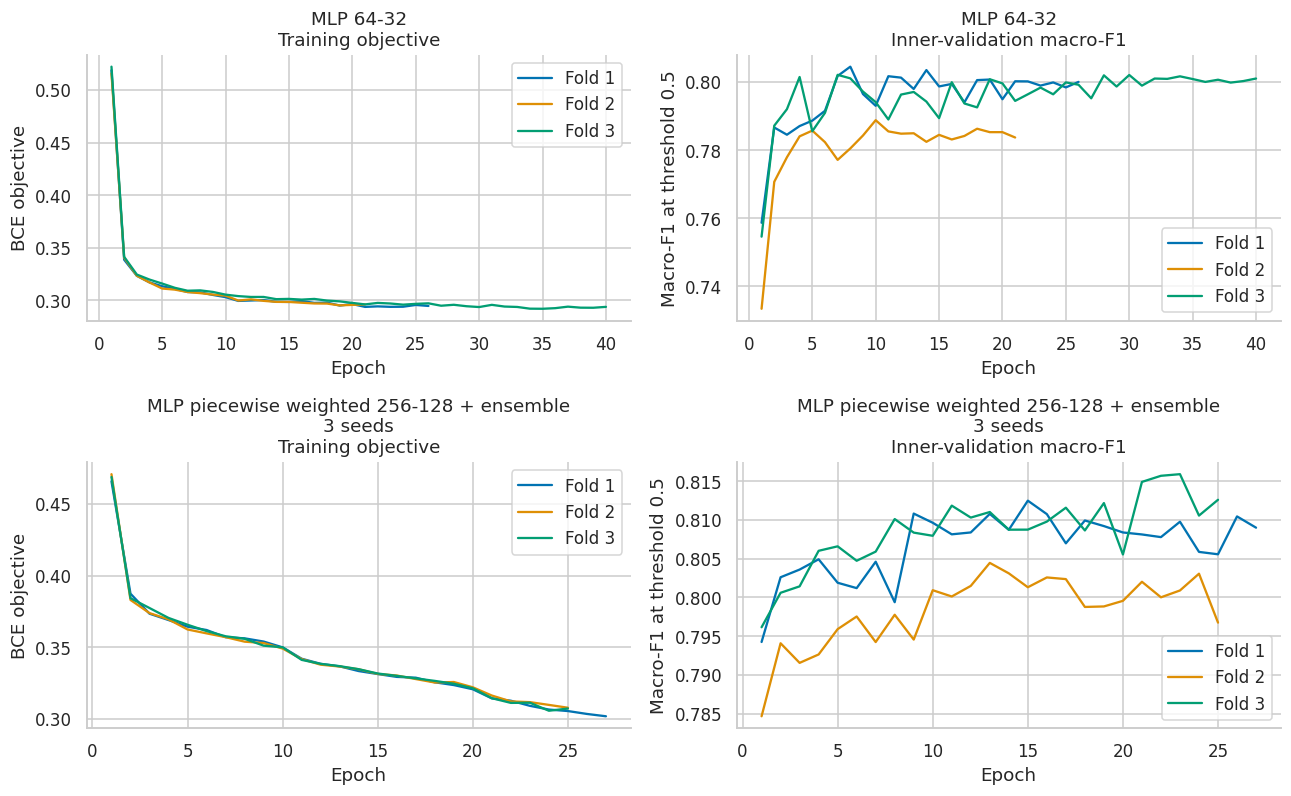

**Interpretation.** The selected fold epoch budgets are [11, 12, 11], giving a final budget of 11 epochs per member. Its mean train–outer-CV macro-F1 gap is 0.0147. Early stopping monitors inner-validation BCE, not the plotted F1. Losses use candidate-specific class weights and should not be compared directly across configurations. Averaged member F1 curves are not ensemble F1 curves.

In [17]:
curve_models = list(dict.fromkeys(["MLP 64-32", dl_config.name]))
fig, axes = plt.subplots(len(curve_models), 2, figsize=(12, 3.7 * len(curve_models)), squeeze=False)
for row, name in enumerate(curve_models):
    for fold, history in dl_history.loc[dl_history["model"] == name].groupby("fold"):
        axes[row, 0].plot(history["epoch"], history["train_loss"], label=f"Fold {fold}")
        axes[row, 1].plot(history["epoch"], history["validation_f1_macro"], label=f"Fold {fold}")
    title = textwrap.fill(name, 42)
    axes[row, 0].set(title=title + "\nTraining objective", xlabel="Epoch", ylabel="BCE objective")
    axes[row, 1].set(title=title + "\nInner-validation macro-F1", xlabel="Epoch", ylabel="Macro-F1 at threshold 0.5")
    for ax in axes[row]:
        ax.legend()
figure(fig, "learning_curves")
selected_folds = dl_fold_results.loc[dl_fold_results["model"] == dl_config.name]
selected_gap = float(dl_cv_results.iloc[0]["f1_macro_gap"])
interpret(f"The selected fold epoch budgets are {selected_folds['best_epoch'].astype(int).tolist()}, giving a final budget of "
          f"{dl_epochs} epochs per member. Its mean train–outer-CV macro-F1 gap is {selected_gap:.4f}. "
          "Early stopping monitors inner-validation BCE, not the plotted F1. Losses use candidate-specific class weights and "
          "should not be compared directly across configurations. Averaged member F1 curves are not ensemble F1 curves.")

## 14. Cross-family comparison

Compare CV results before viewing test performance. Error bars represent fold SD, not confidence intervals.

,model,cv_f1_macro,cv_f1_macro_std,cv_precision_>50K,cv_recall_>50K
0,MLP piecewise weighted 256-128 + ensemble 3 seeds,0.8140,0.0006,0.6997,0.7428
1,MLP piecewise weighted 256-128,0.8126,0.0020,0.6972,0.7424
2,MLP piecewise weighted + ensemble 3 seeds,0.8096,0.0024,0.6934,0.7352
3,MLP piecewise weighted,0.8077,0.0013,0.6976,0.7231
4,MLP piecewise 256-128,0.8061,0.0022,0.7619,0.6455
5,MLP piecewise 128-64,0.8029,0.0027,0.7639,0.6337
6,Random Forest,0.8015,0.0012,0.7727,0.6221
7,Random Forest tuned,0.8015,0.0012,0.7727,0.6221
8,MLP quantile weighted,0.8003,0.0024,0.6743,0.7301
9,MLP quantile 256-128,0.7987,0.0037,0.7332,0.6497


**Interpretation.** Among the two final candidates, **MLP piecewise weighted 256-128 + ensemble 3 seeds** is preferred by CV. The neural-minus-RF macro-F1 difference is +0.0125. This decision is recorded before test evaluation and will not be reversed using test scores.

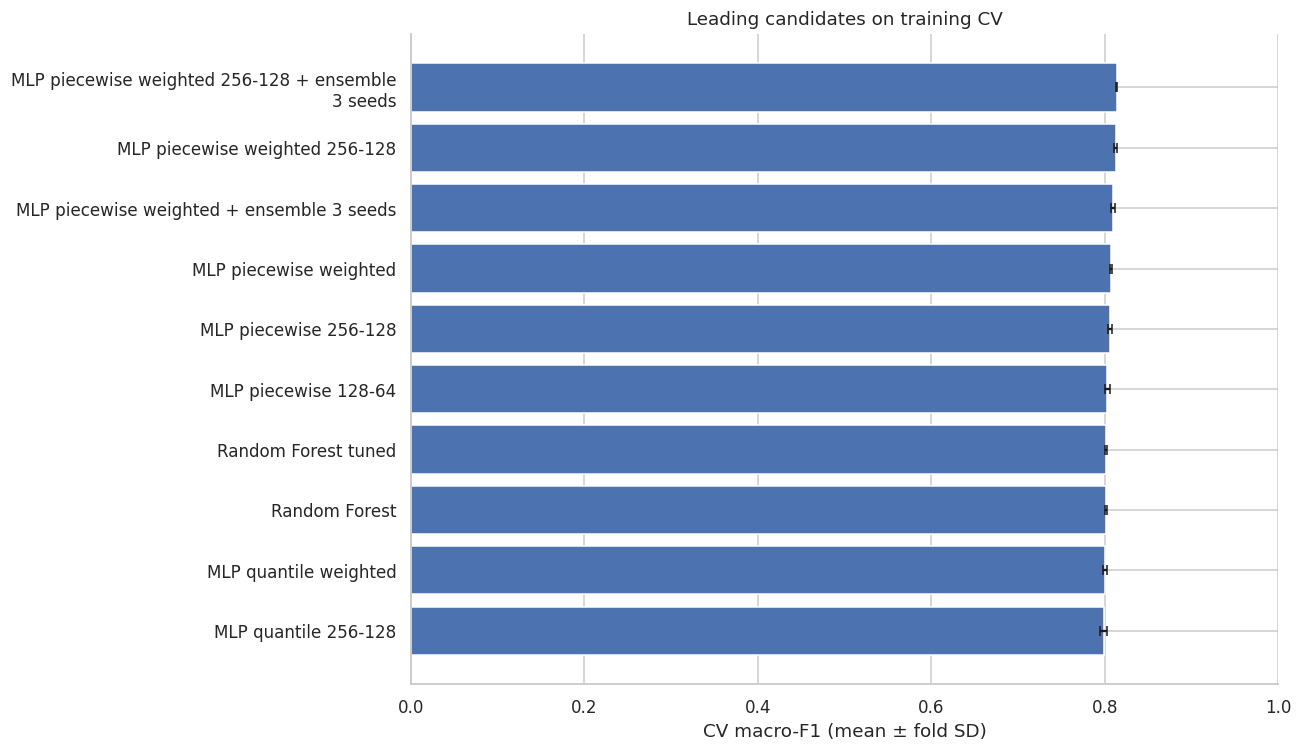

**Interpretation.** The plot summarizes configurations selected using these same folds. Small differences and three fold-level observations do not establish statistical significance. The neural search is larger than the RF grid, so this is not an equal-budget comparison.

In [18]:
rf_cv_row = rf_tuning_results.iloc[[0]].assign(model=RF_NAME)
all_cv_results = pd.concat([comparison_results, rf_cv_row, dl_cv_results], ignore_index=True)
all_cv_results = all_cv_results.sort_values("cv_f1_macro", ascending=False, kind="stable").reset_index(drop=True)
all_cv_results.to_csv(RESULTS / "all_cv_results.csv", index=False)
top = all_cv_results.head(10).copy()
if RF_NAME not in set(top["model"]):
    top = pd.concat([top, rf_cv_row], ignore_index=True)
table(top, "cv_leading_candidates", ["model", "cv_f1_macro", "cv_f1_macro_std", "cv_precision_>50K", "cv_recall_>50K"])
preferred_model_by_cv = dl_config.name if dl_best_cv > rf_search.best_score_ else RF_NAME
interpret(f"Among the two final candidates, **{preferred_model_by_cv}** is preferred by CV. "
          f"The neural-minus-RF macro-F1 difference is {dl_best_cv - rf_search.best_score_:+.4f}. "
          "This decision is recorded before test evaluation and will not be reversed using test scores.")
chart = top.sort_values("cv_f1_macro")
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(np.arange(len(chart)), chart["cv_f1_macro"], xerr=chart["cv_f1_macro_std"], capsize=3, color="#4C72B0")
ax.set_yticks(np.arange(len(chart)), [textwrap.fill(name, 42) for name in chart["model"]])
ax.set(xlim=(0, 1), xlabel="CV macro-F1 (mean ± fold SD)", title="Leading candidates on training CV")
figure(fig, "cv_comparison")
interpret("The plot summarizes configurations selected using these same folds. Small differences and three fold-level observations "
          "do not establish statistical significance. The neural search is larger than the RF grid, so this is not an equal-budget comparison.")

## 15. Final neural fit and decision lock

Refit the chosen neural architecture on all training rows using the CV-selected epoch budget.

In [19]:
final_dl_model, dl_final_history = timed("neural_full_train_refit", dl.fit_final_deep_learning,
    X_train, y_train, dl_config, epochs=dl_epochs, seed=SEED, device=DEVICE)
dl_final_history.to_csv(RESULTS / "deep_learning_final_history.csv", index=False)
member_seeds = [int((SEED + 1009 * member) % (2**32 - 1)) for member in range(dl_config.ensemble_size)]
selection = {"preferred_model": preferred_model_by_cv, "selection_metric": "3-fold CV macro-F1",
    "rf_cv_macro_f1": float(rf_search.best_score_), "neural_cv_macro_f1": dl_best_cv,
    "rf_params": rf_search.best_params_, "neural_config": asdict(dl_config),
    "epochs_per_member": dl_epochs, "member_seeds": member_seeds, "threshold": 0.5,
    "test_used_for_selection": False, "locked_at_utc": datetime.now(timezone.utc).isoformat()}
save_json(RESULTS / "selection_before_test.json", selection)
fit_summary = pd.DataFrame([
    {"model": RF_NAME, "training_rows": len(X_train), "members": 200, "member_type": "trees", "epochs_per_member": None},
    {"model": dl_config.name, "training_rows": len(X_train), "members": dl_config.ensemble_size,
     "member_type": "neural networks", "epochs_per_member": dl_epochs},
])
table(fit_summary, "final_fit_summary")
interpret(f"Both finalists are now fitted and frozen. Neural initialization seeds are {member_seeds}; "
          "each member uses the complete training partition and the same fixed epoch budget. "
          "Both classifiers retain their threshold of 0.5; test labels have not determined epochs, weights or thresholds.")

*Completed neural_full_train_refit in 61.8 seconds.*

,model,training_rows,members,member_type,epochs_per_member
0,Random Forest tuned,32561,200,trees,NaN
1,MLP piecewise weighted 256-128 + ensemble 3 seeds,32561,3,neural networks,11.0


**Interpretation.** Both finalists are now fitted and frozen. Neural initialization seeds are [42, 1051, 2060]; each member uses the complete training partition and the same fixed epoch budget. Both classifiers retain their threshold of 0.5; test labels have not determined epochs, weights or thresholds.

## 16. Test-set performance

Evaluate the two frozen finalists on the official UCI test partition. These measurements are not fed back into selection.

In [20]:
X_test, y_test = prepare_xy(test_df, feature_columns=X_train.columns)
rf_test_results, rf_report, rf_predictions = evaluate_test(final_rf_model, X_test, y_test)
rf_test_results["model"] = RF_NAME
dl_test_results, dl_report, dl_predictions = dl.evaluate_deep_learning_test(final_dl_model, X_test, y_test)
test_comparison = pd.concat([rf_test_results, dl_test_results], ignore_index=True)
table(test_comparison, "test_comparison", ["model", "test_accuracy", "test_f1_macro", "test_f1_>50K", "test_roc_auc", "test_average_precision"])
rf_test, neural_test = rf_test_results.iloc[0], dl_test_results.iloc[0]
test_delta = float(neural_test["test_f1_macro"] - rf_test["test_f1_macro"])
selected_test = test_comparison.set_index("model").loc[preferred_model_by_cv]
selected_cv = dl_best_cv if preferred_model_by_cv == dl_config.name else float(rf_search.best_score_)
interpret(f"The neural-minus-RF test macro-F1 difference is {test_delta:+.4f}. "
          f"The CV-selected model remains **{preferred_model_by_cv}**, with test macro-F1 {selected_test['test_f1_macro']:.4f} "
          f"and a test-minus-CV difference of {selected_test['test_f1_macro'] - selected_cv:+.4f}. "
          "These are follow-up benchmark results on the previously examined UCI test set, not a guarantee of future performance.")
rf_scores = final_rf_model.predict_proba(X_test)[:, list(final_rf_model.classes_).index(1)]
dl_scores = final_dl_model.predict_proba(X_test)[:, 1]
predictions_table = pd.DataFrame({"actual": np.asarray(y_test),
    "rf_prediction": rf_predictions, "rf_probability": rf_scores,
    "neural_prediction": dl_predictions, "neural_probability": dl_scores})
assert np.isfinite(predictions_table.to_numpy()).all()
predictions_table.to_csv(RESULTS / "test_predictions.csv", index=False)

,model,test_accuracy,test_f1_macro,test_f1_>50K,test_roc_auc,test_average_precision
0,Random Forest tuned,0.8628,0.7949,0.6768,0.9149,0.7965
1,MLP piecewise weighted 256-128 + ensemble 3 seeds,0.8607,0.8109,0.7139,0.9230,0.8131


**Interpretation.** The neural-minus-RF test macro-F1 difference is +0.0160. The CV-selected model remains **MLP piecewise weighted 256-128 + ensemble 3 seeds**, with test macro-F1 0.8109 and a test-minus-CV difference of -0.0031. These are follow-up benchmark results on the previously examined UCI test set, not a guarantee of future performance.

## 17. Class-specific performance

Separate minority-class detection from aggregate accuracy.

In [21]:
for name, report in ((RF_NAME, rf_report), (dl_config.name, dl_report)):
    report_frame = pd.DataFrame(report).T.loc[["<=50K", ">50K", "macro avg", "weighted avg"]].copy()
    report_frame["support"] = report_frame["support"].astype(int)
    display(Markdown(f"**{name}**"))
    table(report_frame, "rf_classification_report" if name == RF_NAME else "neural_classification_report")
    positive = report_frame.loc[">50K"]
    interpret(f"For >50K, precision is {positive['precision']:.2%} and recall is {positive['recall']:.2%}, "
              f"with F1 {positive['f1-score']:.4f}. The weighted average is influenced more heavily by the majority class, "
              "whereas macro averages give both classes equal weight.")

**Random Forest tuned**

,precision,recall,f1-score,support
<=50K,0.8859,0.9417,0.9130,12435
>50K,0.7633,0.6079,0.6768,3846
macro avg,0.8246,0.7748,0.7949,16281
weighted avg,0.8569,0.8628,0.8572,16281


**Interpretation.** For >50K, precision is 76.33% and recall is 60.79%, with F1 0.6768. The weighted average is influenced more heavily by the majority class, whereas macro averages give both classes equal weight.

**MLP piecewise weighted 256-128 + ensemble 3 seeds**

,precision,recall,f1-score,support
<=50K,0.9166,0.8994,0.9079,12435
>50K,0.6934,0.7356,0.7139,3846
macro avg,0.8050,0.8175,0.8109,16281
weighted avg,0.8639,0.8607,0.8621,16281


**Interpretation.** For >50K, precision is 69.34% and recall is 73.56%, with F1 0.7139. The weighted average is influenced more heavily by the majority class, whereas macro averages give both classes equal weight.

## 18. Error analysis

Inspect false negatives and false positives at the frozen threshold.

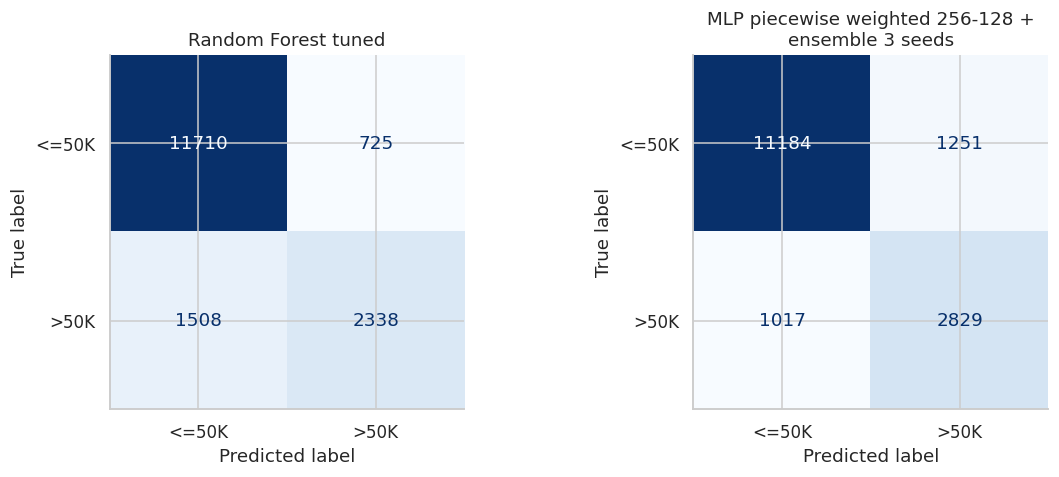

**Interpretation.** RF misses 1,508 positive cases; the neural model misses 1,017. Their false-positive counts are 725 and 1,251, respectively. A model that misses fewer high-income records may also label more low-income records as positive.

,true_negative,false_positive,false_negative,true_positive
model,,,,
Random Forest tuned,11710,725,1508,2338
MLP piecewise weighted 256-128 + ensemble 3 seeds,11184,1251,1017,2829


**Interpretation.** Relative to RF, the neural model changes false negatives by -491 and false positives by +526. The preferred operational trade-off would require an explicit cost function; this experiment retains its predeclared macro-F1 objective.

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
errors = []
for ax, (name, predicted) in zip(axes, ((RF_NAME, rf_predictions), (dl_config.name, dl_predictions))):
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["<=50K", ">50K"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(textwrap.fill(name, 38))
    tn, fp, fn, tp = matrix.ravel()
    errors.append({"model": name, "true_negative": int(tn), "false_positive": int(fp),
                   "false_negative": int(fn), "true_positive": int(tp)})
figure(fig, "confusion_matrices")
error_table = pd.DataFrame(errors).set_index("model")
fn_rf = int(error_table.loc[RF_NAME, "false_negative"])
fn_dl = int(error_table.loc[dl_config.name, "false_negative"])
fp_rf = int(error_table.loc[RF_NAME, "false_positive"])
fp_dl = int(error_table.loc[dl_config.name, "false_positive"])
interpret(f"RF misses {fn_rf:,} positive cases; the neural model misses {fn_dl:,}. "
          f"Their false-positive counts are {fp_rf:,} and {fp_dl:,}, respectively. "
          "A model that misses fewer high-income records may also label more low-income records as positive.")
table(error_table, "error_counts")
interpret(f"Relative to RF, the neural model changes false negatives by {fn_dl - fn_rf:+,} and false positives by "
          f"{fp_dl - fp_rf:+,}. The preferred operational trade-off would require an explicit cost function; "
          "this experiment retains its predeclared macro-F1 objective.")

## 19. Ranking quality

Use ROC and precision–recall curves to assess score ranking beyond a single decision threshold.

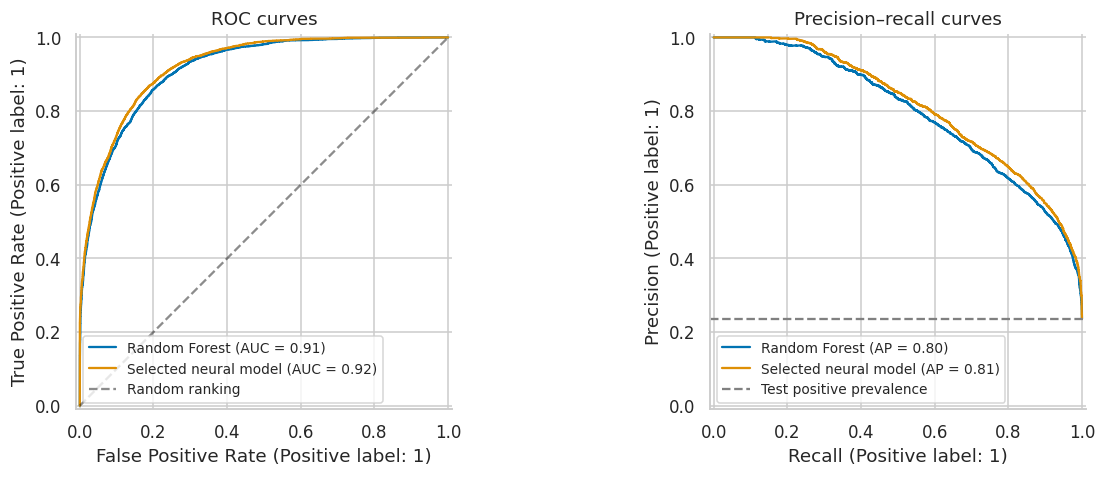

**Interpretation.** RF and the neural model achieve ROC-AUC 0.9149 and 0.9230, and average precision (AP) 0.7965 and 0.8131. AP summarizes precision–recall performance and is not trapezoidal PR-AUC. Neither ranking metric establishes probability calibration.

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in (("Random Forest", rf_scores), ("Selected neural model", dl_scores)):
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random ranking")
axes[1].axhline(float(y_test.mean()), color="gray", linestyle="--", label="Test positive prevalence")
axes[0].set_title("ROC curves")
axes[1].set_title("Precision–recall curves")
for ax in axes:
    ax.legend(fontsize=9)
figure(fig, "roc_precision_recall")
interpret(f"RF and the neural model achieve ROC-AUC {rf_test['test_roc_auc']:.4f} and {neural_test['test_roc_auc']:.4f}, "
          f"and average precision (AP) {rf_test['test_average_precision']:.4f} and {neural_test['test_average_precision']:.4f}. "
          "AP summarizes precision–recall performance and is not trapezoidal PR-AUC. Neither ranking metric establishes probability calibration.")

## 20. Model persistence and feature export

Save the fitted pipelines and verify that reloading preserves predictions. Exported feature arrays belong to the RF pipeline only.

In [24]:
joblib.dump(final_rf_model, MODELS / "random_forest.joblib")
dl.save_deep_learning_model(final_dl_model, MODELS / "deep_learning")
restored_rf = joblib.load(MODELS / "random_forest.joblib")
restored_dl = dl.load_deep_learning_model(MODELS / "deep_learning", device=DEVICE)
sample = X_test.iloc[:256]
np.testing.assert_allclose(restored_rf.predict_proba(sample), final_rf_model.predict_proba(sample), rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(restored_dl.predict_proba(sample), final_dl_model.predict_proba(sample), rtol=1e-6, atol=1e-7)
feature_summary = export_features(final_rf_model.named_steps["preprocessor"],
    X_train, X_test, y_train, y_test, output_dir=FEATURES,
    metadata={"owner_model": RF_NAME, "source_commit": SOURCE_REF,
              "usage": "RF feature export only; neural inference accepts the original feature DataFrame"})
table(feature_summary, "feature_export")
checks = {"official_partition_shapes": True, "finite_test_predictions": True,
    "rf_reload_matches": True, "neural_reload_matches": True, "feature_roundtrip_matches": True,
    "source_integrity_matches": True, "finalist_selection_locked_before_test": True}
save_json(RESULTS / "runtime_checks.json", checks)
interpret("Both reloaded models reproduce the original prediction probabilities on 256 test rows. Exported RF arrays also pass "
          "save/load checks. The neural checkpoint retains its own preprocessor, configuration and all member weights; "
          "RF-transformed arrays must not be passed into the neural predictor.")

,file,shape,size_MiB
0,X_train_cfg1.npy,"(32561, 105)",26.0843
1,X_test_cfg1.npy,"(16281, 105)",13.0426
2,y_train.npy,"(32561,)",0.2485
3,y_test.npy,"(16281,)",0.1243


**Interpretation.** Both reloaded models reproduce the original prediction probabilities on 256 test rows. Exported RF arrays also pass save/load checks. The neural checkpoint retains its own preprocessor, configuration and all member weights; RF-transformed arrays must not be passed into the neural predictor.

## 21. Conclusions

Summarize the measured outcome, trade-offs and limits of the experiment.

In [25]:
direction = "higher" if test_delta > 0 else "lower" if test_delta < 0 else "equal"
conclusion = f"""### Findings

The experiment used **{len(X_train):,} training records** and **{len(X_test):,} test records** from the official UCI split.
Macro-F1 guided configuration selection on three stratified folds. All preprocessing was fitted within the relevant training split, and the prediction threshold remained **0.5**.

The chosen neural configuration was **{dl_config.name}**, using **{dl_config.ensemble_size} initialization(s)** and **{dl_epochs} full-training epochs per member**.
It achieved CV macro-F1 **{dl_best_cv:.4f} ± {dl_selected_sd:.4f}**, compared with **{rf_search.best_score_:.4f}** for tuned RF.
The pre-test selection was **{preferred_model_by_cv}**.

On the test partition, neural macro-F1 was **{neural_test['test_f1_macro']:.4f}**, {direction} than RF's **{rf_test['test_f1_macro']:.4f}**
(difference **{test_delta:+.4f}**). Neural accuracy was **{neural_test['test_accuracy']:.2%}**, ROC-AUC **{neural_test['test_roc_auc']:.4f}**,
and AP **{neural_test['test_average_precision']:.4f}**. For >50K, neural precision/recall were
**{neural_test['test_precision_>50K']:.2%}/{neural_test['test_recall_>50K']:.2%}**, versus
**{rf_test['test_precision_>50K']:.2%}/{rf_test['test_recall_>50K']:.2%}** for RF.
False negatives were **{fn_dl:,}** for the neural model and **{fn_rf:,}** for RF. These differences must be interpreted alongside false positives and application-specific error costs.

### Limitations and next steps

These results apply to the tested configurations and one outer-fold partition seed. Ensemble initializations are not repeated independent dataset splits.
The search used **{len(dl.DEFAULT_CONFIGS)} neural configurations plus two shortlisted ensembles**, compared with **12 RF configurations**; computational budgets are unequal.
CV scores were reused for selection and may be optimistic. The official test set had been examined previously, so the current evaluation is a follow-up benchmark.
No significance test, external validation, calibration study or subgroup-fairness assessment was performed; exact training duplicates were retained.
Further work should use repeated or nested training-only validation and a genuinely new final holdout, rather than adapting the model to these test outcomes.
"""
display(Markdown(conclusion))
(RESULTS / "conclusion.txt").write_text(conclusion, encoding="utf-8")

### Findings

The experiment used **32,561 training records** and **16,281 test records** from the official UCI split. 
Macro-F1 guided configuration selection on three stratified folds. All preprocessing was fitted within the relevant training split, and the prediction threshold remained **0.5**.

The chosen neural configuration was **MLP piecewise weighted 256-128 + ensemble 3 seeds**, using **3 initialization(s)** and **11 full-training epochs per member**. 
It achieved CV macro-F1 **0.8140 ± 0.0006**, compared with **0.8015** for tuned RF. 
The pre-test selection was **MLP piecewise weighted 256-128 + ensemble 3 seeds**.

On the test partition, neural macro-F1 was **0.8109**, higher than RF's **0.7949** 
(difference **+0.0160**). Neural accuracy was **86.07%**, ROC-AUC **0.9230**, 
and AP **0.8131**. For >50K, neural precision/recall were 
**69.34%/73.56%**, versus 
**76.33%/60.79%** for RF. 
False negatives were **1,017** for the neural model and **1,508** for RF. These differences must be interpreted alongside false positives and application-specific error costs.

### Limitations and next steps

These results apply to the tested configurations and one outer-fold partition seed. Ensemble initializations are not repeated independent dataset splits. 
The search used **16 neural configurations plus two shortlisted ensembles**, compared with **12 RF configurations**; computational budgets are unequal. 
CV scores were reused for selection and may be optimistic. The official test set had been examined previously, so the current evaluation is a follow-up benchmark. 
No significance test, external validation, calibration study or subgroup-fairness assessment was performed; exact training duplicates were retained. 
Further work should use repeated or nested training-only validation and a genuinely new final holdout, rather than adapting the model to these test outcomes.


1899

## 22. Export experiment artifacts

Package this run’s metrics, predictions, figures, fitted models, source snapshots and reproducibility metadata.

In [26]:
for relative in SOURCE_HASHES:
    destination = RUN_DIR / "source" / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(PROJECT_DIR / relative, destination)
pd.DataFrame(timings).to_csv(RESULTS / "stage_timings.csv", index=False)
manifest = []
for path in sorted(RUN_DIR.rglob("*")):
    if path.is_file():
        manifest.append({"file": path.relative_to(RUN_DIR).as_posix(), "bytes": path.stat().st_size,
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
pd.DataFrame(manifest).to_csv(RUN_DIR / "manifest.csv", index=False)
archive_path = BASE_DIR / f"adult_census_results_{RUN_ID}.zip"
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(RUN_DIR.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(RUN_DIR))
with ZipFile(archive_path) as archive:
    assert archive.testzip() is None
export_summary = pd.DataFrame([{"artifact_files": len(manifest) + 1,
    "archive_MiB": archive_path.stat().st_size / 1024**2,
    "measured_training_seconds": sum(row["seconds"] for row in timings),
    "runtime_checks_passed": all(checks.values())}])
display(export_summary.round(2))
interpret("The output archive passed its integrity check. It contains this run's results and source snapshots; "
          "the checksum manifest supports verification. In Colab, download the ZIP from the Files panel.")
display(FileLink(str(archive_path)))
print("Results directory:", RUN_DIR)

,artifact_files,archive_MiB,measured_training_seconds,runtime_checks_passed
0,60,15.59,1561.08,True


**Interpretation.** The output archive passed its integrity check. It contains this run's results and source snapshots; the checksum manifest supports verification. In Colab, download the ZIP from the Files panel.

/content/adult_census_results_20261125_165955_392032.zip

Results directory: /content/adult_census_english/runs/20261125_165955_392032


## References

- [UCI Adult dataset](https://archive.ics.uci.edu/dataset/2/adult).
- [Project source](https://github.com/Tri8505/ML-Assignment-Adult-Census).
- [Gorishniy et al., *On Embeddings for Numerical Features in Tabular Deep Learning*, NeurIPS 2022](https://arxiv.org/abs/2203.05556). The module uses a piecewise-linear encoding inspired by this work, with knots derived from distinct observed training values.